<a href="https://colab.research.google.com/github/aannddrree/disciplinaIA/blob/main/aula_pratica_agendamento_processos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula prática: Agendamento de Processos

Neste notebook você vai simular algoritmos de escalonamento. A ideia é experimentar: altere chegadas, bursts e quantum e observe o efeito.

**Conceitos mínimos**
- **Processo**: programa em execução.
- **Burst de CPU**: tempo de CPU que ele precisa.
- **Chegada**: momento em que ele entra na fila de prontos.
- **Escalonador**: regra que decide quem recebe a CPU.

In [1]:
from collections import deque
from dataclasses import dataclass
import matplotlib.pyplot as plt

@dataclass
class Processo:
    nome: str
    chegada: int
    burst: int

processos = [
    Processo('P1', 0, 6),
    Processo('P2', 1, 2),
    Processo('P3', 2, 4),
    Processo('P4', 3, 1),
]
processos

[Processo(nome='P1', chegada=0, burst=6),
 Processo(nome='P2', chegada=1, burst=2),
 Processo(nome='P3', chegada=2, burst=4),
 Processo(nome='P4', chegada=3, burst=1)]

## 1. Funções de apoio
Cada algoritmo vai devolver uma lista de fatias de execução no formato `(início, fim, processo)`. Isso nos permite desenhar uma linha do tempo.

In [2]:
CORES = {'P1':'#1677c8', 'P2':'#11a6a0', 'P3':'#f59f00', 'P4':'#7c3aed'}

def gantt(linha, titulo):
    fig, ax = plt.subplots(figsize=(12, 2.2))
    for inicio, fim, nome in linha:
        ax.barh(0, fim-inicio, left=inicio, color=CORES.get(nome, '#64748b'), edgecolor='white', height=.55)
        ax.text((inicio+fim)/2, 0, nome, ha='center', va='center', color='white', weight='bold')
        ax.text(inicio, -.38, str(inicio), ha='center')
    ax.text(linha[-1][1], -.38, str(linha[-1][1]), ha='center')
    ax.set_yticks([]); ax.set_xlabel('tempo (ms)'); ax.set_title(titulo); ax.spines[['top','right','left']].set_visible(False)
    plt.show()

def metricas(linha, processos):
    dados = []
    for p in processos:
        fatias = [(i, f) for i, f, nome in linha if nome == p.nome]
        inicio, fim = fatias[0][0], fatias[-1][1]
        resposta = inicio - p.chegada
        retorno = fim - p.chegada
        espera = retorno - p.burst
        dados.append((p.nome, resposta, espera, retorno))
    return dados

def mostrar_metricas(linha, processos):
    dados = metricas(linha, processos)
    print('Processo | Resposta | Espera | Retorno')
    for d in dados: print(f'{d[0]:>8} | {d[1]:>8} | {d[2]:>6} | {d[3]:>7}')
    medias = [sum(x[i] for x in dados)/len(dados) for i in (1,2,3)]
    print(f'Médias   | {medias[0]:8.2f} | {medias[1]:6.2f} | {medias[2]:7.2f}')

## 2. FCFS — First Come, First Served
O primeiro processo que chega executa primeiro e mantém a CPU até concluir. É como uma fila comum.

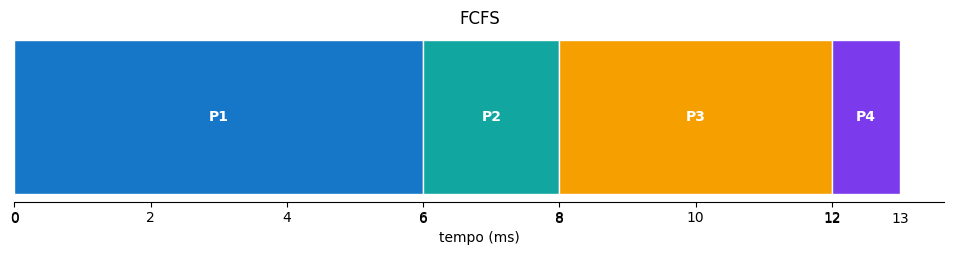

Processo | Resposta | Espera | Retorno
      P1 |        0 |      0 |       6
      P2 |        5 |      5 |       7
      P3 |        6 |      6 |      10
      P4 |        9 |      9 |      10
Médias   |     5.00 |   5.00 |    8.25


In [3]:
def fcfs(processos):
    tempo, linha = 0, []
    for p in sorted(processos, key=lambda x: x.chegada):
        tempo = max(tempo, p.chegada)  # CPU pode ficar ociosa
        linha.append((tempo, tempo + p.burst, p.nome))
        tempo += p.burst
    return linha

linha_fcfs = fcfs(processos)
gantt(linha_fcfs, 'FCFS')
mostrar_metricas(linha_fcfs, processos)

**Pergunta:** P2 precisa de apenas 2 ms. Por que ele espera tanto no FCFS?

Resposta: P1 chegou antes e usa a CPU até terminar. Esse efeito é chamado de *convoy effect*: um processo longo atrasa vários processos curtos.

## 3. Round Robin
Cada processo recebe um **quantum**. Ao consumir esse tempo, volta ao fim da fila se ainda não terminou. Isso dá oportunidade para vários processos executarem cedo.

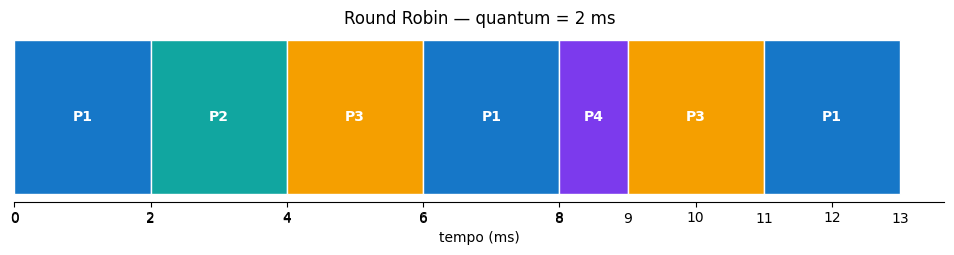

Processo | Resposta | Espera | Retorno
      P1 |        0 |      7 |      13
      P2 |        1 |      1 |       3
      P3 |        2 |      5 |       9
      P4 |        5 |      5 |       6
Médias   |     2.00 |   4.50 |    7.75


In [4]:
def round_robin(processos, quantum=2):
    pendentes = deque(sorted(processos, key=lambda x: x.chegada))
    fila, tempo, linha = deque(), 0, []
    restantes = {p.nome: p.burst for p in processos}
    while pendentes or fila:
        while pendentes and pendentes[0].chegada <= tempo:
            fila.append(pendentes.popleft())
        if not fila:
            tempo = pendentes[0].chegada
            continue
        p = fila.popleft()
        uso = min(quantum, restantes[p.nome])
        linha.append((tempo, tempo + uso, p.nome))
        tempo += uso
        restantes[p.nome] -= uso
        while pendentes and pendentes[0].chegada <= tempo:
            fila.append(pendentes.popleft())
        if restantes[p.nome] > 0:
            fila.append(p)
    return linha

quantum = 2
linha_rr = round_robin(processos, quantum)
gantt(linha_rr, f'Round Robin — quantum = {quantum} ms')
mostrar_metricas(linha_rr, processos)

## 4. Experimento: o quantum muda o resultado
Execute a célula e compare. Quantum pequeno costuma melhorar a resposta, mas cria mais trocas de contexto.

In [5]:
for q in [1, 2, 4]:
    linha = round_robin(processos, q)
    espera_media = sum(x[2] for x in metricas(linha, processos)) / len(processos)
    print(f'quantum={q}: {len(linha)} fatias de CPU; espera média={espera_media:.2f} ms')

quantum=1: 13 fatias de CPU; espera média=4.25 ms
quantum=2: 7 fatias de CPU; espera média=4.50 ms
quantum=4: 5 fatias de CPU; espera média=5.25 ms


## 5. Comparação das estratégias

| Estratégia | Analogia | Quando funciona bem | Principal limitação |
|---|---|---|---|
| **FCFS** | Fila de banco: quem chegou antes é atendido primeiro | Processamento em lote simples | Um trabalho longo prende os curtos atrás dele |
| **Round Robin** | Roda de conversa: cada pessoa fala por um tempo fixo | Sistemas interativos, como desktops e servidores compartilhados | Quantum muito pequeno gera muitas trocas de contexto |
| **SJF** | Caixa rápido: atende primeiro quem tem poucos itens | Quando o tempo de CPU pode ser estimado | Processos longos podem esperar demais |
| **Prioridades** | Pronto-socorro: casos urgentes recebem atendimento primeiro | Quando algumas tarefas são mais importantes | Baixa prioridade pode sofrer starvation |

**Como decidir?** Se a prioridade é simplicidade, FCFS pode bastar. Se a pessoa usuária precisa perceber resposta rápida, Round Robin é mais adequado. Se a meta é reduzir a espera média, SJF costuma ser melhor quando as estimativas são confiáveis.

## 6. Código completo comentado
A célula abaixo reúne os algoritmos com comentários. Leia os comentários antes de executar e compare o resultado com os gráficos anteriores.

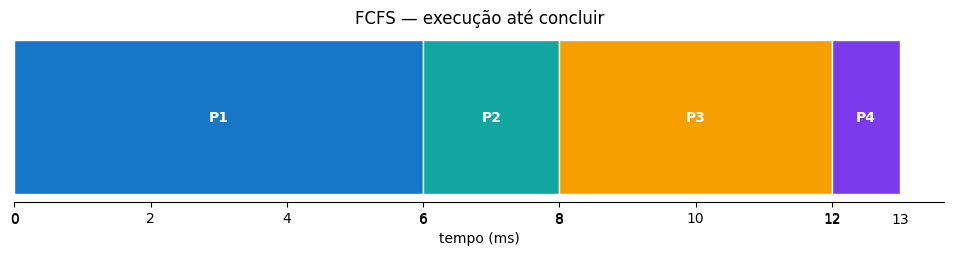

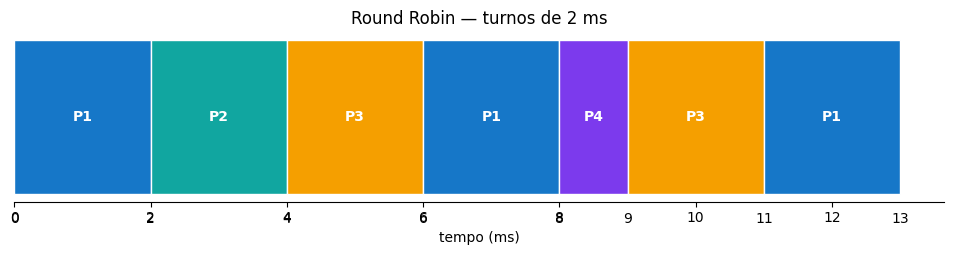

Processo | Resposta | Espera | Retorno
      P1 |        0 |      0 |       6
      P2 |        5 |      5 |       7
      P3 |        6 |      6 |      10
      P4 |        9 |      9 |      10
Médias   |     5.00 |   5.00 |    8.25
Processo | Resposta | Espera | Retorno
      P1 |        0 |      7 |      13
      P2 |        1 |      1 |       3
      P3 |        2 |      5 |       9
      P4 |        5 |      5 |       6
Médias   |     2.00 |   4.50 |    7.75


In [6]:
# Importa deque, uma fila eficiente: inserir e retirar nas extremidades é rápido.
from collections import deque

def fcfs_comentado(processos):
    # O relógio da simulação começa no instante zero.
    tempo = 0
    # A linha do tempo guardará tuplas: (início, fim, nome do processo).
    linha = []
    # FCFS ordena somente pela chegada. Quem chegou antes entra primeiro.
    for p in sorted(processos, key=lambda processo: processo.chegada):
        # Se nenhum processo estiver pronto, a CPU fica ociosa até a próxima chegada.
        tempo = max(tempo, p.chegada)
        # Em FCFS, o processo recebe todo o burst de uma vez. Não há preempção.
        inicio = tempo
        fim = inicio + p.burst
        linha.append((inicio, fim, p.nome))
        # Quando ele termina, a CPU fica disponível para o próximo.
        tempo = fim
    return linha

def round_robin_comentado(processos, quantum):
    # Pendentes contém processos que ainda não chegaram ao sistema.
    pendentes = deque(sorted(processos, key=lambda processo: processo.chegada))
    # fila é a fila de prontos: processos que já chegaram e podem usar a CPU.
    fila = deque()
    # restante registra quanto de CPU cada processo ainda precisa.
    restante = {p.nome: p.burst for p in processos}
    tempo = 0
    linha = []

    # Continue enquanto existir processo por chegar ou processo pronto.
    while pendentes or fila:
        # Mova para a fila todos os processos que chegaram até o instante atual.
        while pendentes and pendentes[0].chegada <= tempo:
            fila.append(pendentes.popleft())

        # Se a fila estiver vazia, não há trabalho pronto. Pule para a próxima chegada.
        if not fila:
            tempo = pendentes[0].chegada
            continue

        # Round Robin retira o primeiro processo pronto.
        p = fila.popleft()
        # Ele usa no máximo um quantum, mas pode terminar antes disso.
        uso = min(quantum, restante[p.nome])
        linha.append((tempo, tempo + uso, p.nome))
        tempo += uso
        restante[p.nome] -= uso

        # Processos que chegaram durante esse turno também entram na fila.
        while pendentes and pendentes[0].chegada <= tempo:
            fila.append(pendentes.popleft())
        # Se ainda falta CPU, o processo volta ao fim da fila e aguarda novo turno.
        if restante[p.nome] > 0:
            fila.append(p)
    return linha

# Execute os dois algoritmos sobre a mesma carga para uma comparação justa.
linha_fcfs_comentada = fcfs_comentado(processos)
linha_rr_comentada = round_robin_comentado(processos, quantum=2)

gantt(linha_fcfs_comentada, 'FCFS — execução até concluir')
gantt(linha_rr_comentada, 'Round Robin — turnos de 2 ms')
mostrar_metricas(linha_fcfs_comentada, processos)
mostrar_metricas(linha_rr_comentada, processos)

## 7. Desafio — P4, Round Robin e SJF

Foi adicionado o processo **P4**, com chegada no instante 3 e burst de 1 ms.

Comparamos FCFS e Round Robin com quantums 1, 2 e 4. Depois, implementamos SJF não preemptivo: quando a CPU fica livre, escolhe, entre os processos que já chegaram, aquele que possui o menor burst.

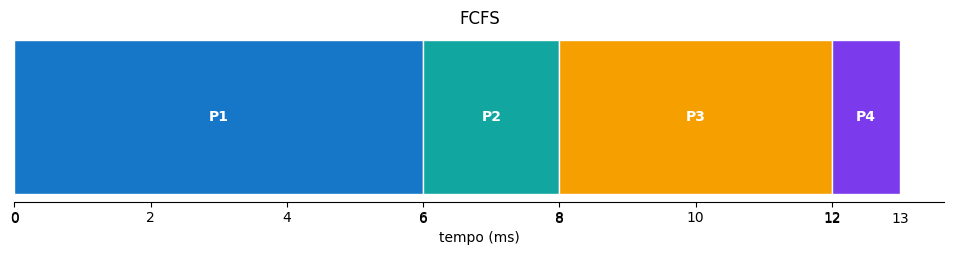

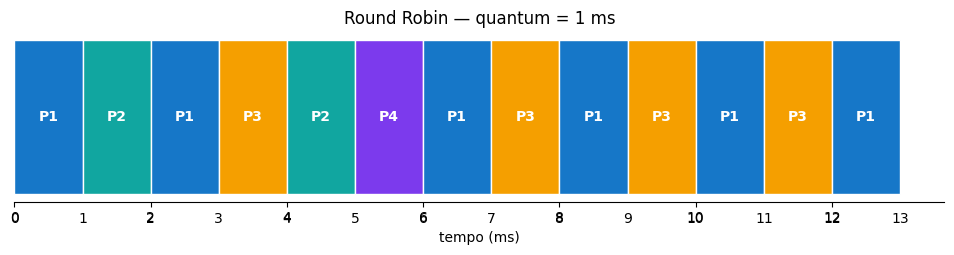

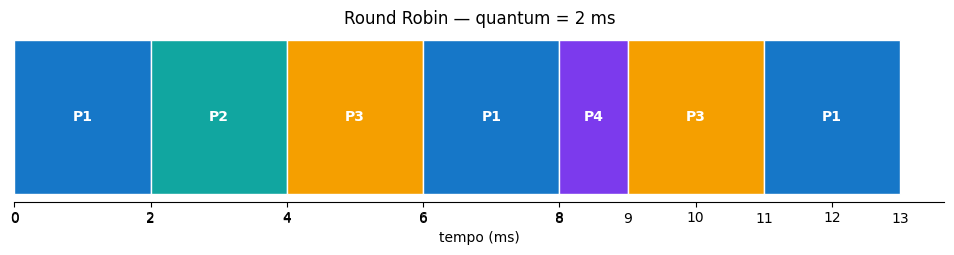

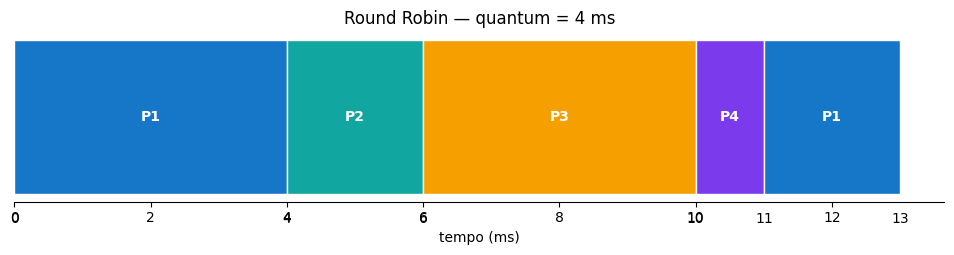

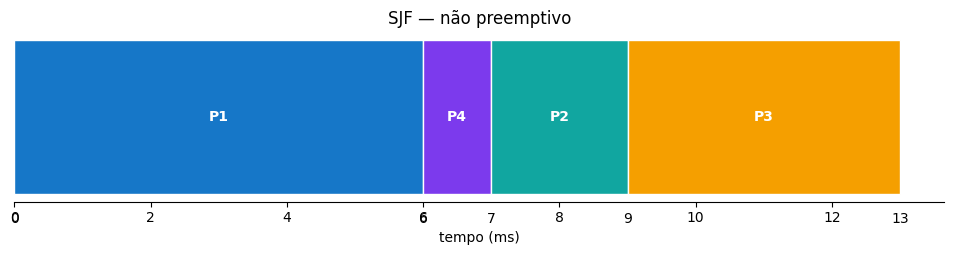

FCFS
Processo | Resposta | Espera | Retorno
      P1 |        0 |      0 |       6
      P2 |        5 |      5 |       7
      P3 |        6 |      6 |      10
      P4 |        9 |      9 |      10
Médias   |     5.00 |   5.00 |    8.25
\nRound Robin — quantum = 1
Processo | Resposta | Espera | Retorno
      P1 |        0 |      7 |      13
      P2 |        0 |      2 |       4
      P3 |        1 |      6 |      10
      P4 |        2 |      2 |       3
Médias   |     0.75 |   4.25 |    7.50
\nRound Robin — quantum = 2
Processo | Resposta | Espera | Retorno
      P1 |        0 |      7 |      13
      P2 |        1 |      1 |       3
      P3 |        2 |      5 |       9
      P4 |        5 |      5 |       6
Médias   |     2.00 |   4.50 |    7.75
\nRound Robin — quantum = 4
Processo | Resposta | Espera | Retorno
      P1 |        0 |      7 |      13
      P2 |        3 |      3 |       5
      P3 |        4 |      4 |       8
      P4 |        7 |      7 |       8
Médias   |    

In [7]:
def sjf(processos):
    pendentes = sorted(processos, key=lambda p: p.chegada)
    prontos = []
    tempo = 0
    linha = []

    while pendentes or prontos:
        # Coloca na fila os processos que já chegaram.
        while pendentes and pendentes[0].chegada <= tempo:
            prontos.append(pendentes.pop(0))

        # Se não há processo pronto, avança até a próxima chegada.
        if not prontos:
            tempo = pendentes[0].chegada
            continue

        # Escolhe o menor burst; em empate, vence quem chegou primeiro.
        escolhido = min(prontos, key=lambda p: (p.burst, p.chegada))
        prontos.remove(escolhido)

        # SJF não preemptivo: executa até terminar.
        inicio = tempo
        fim = inicio + escolhido.burst
        linha.append((inicio, fim, escolhido.nome))
        tempo = fim

    return linha


# Executa os algoritmos e gera os gráficos de Gantt.
linha_fcfs = fcfs(processos)
linhas_rr = {q: round_robin(processos, q) for q in [1, 2, 4]}
linha_sjf = sjf(processos)

gantt(linha_fcfs, 'FCFS')
for q, linha in linhas_rr.items():
    gantt(linha, f'Round Robin — quantum = {q} ms')
gantt(linha_sjf, 'SJF — não preemptivo')

# Compara as métricas.
print('FCFS')
mostrar_metricas(linha_fcfs, processos)
for q, linha in linhas_rr.items():
    print(f'\\nRound Robin — quantum = {q}')
    mostrar_metricas(linha, processos)
print('\\nSJF')
mostrar_metricas(linha_sjf, processos)

# Mostra o instante em que P4 começa em cada política.
def inicio_processo(linha, nome):
    return next(inicio for inicio, fim, processo in linha if processo == nome)

print('\\nInício de P4:')
print(f'FCFS: {inicio_processo(linha_fcfs, "P4")} ms')
for q, linha in linhas_rr.items():
    print(f'Round Robin (Q={q}): {inicio_processo(linha, "P4")} ms')
print(f'SJF: {inicio_processo(linha_sjf, "P4")} ms')

## 8. Conclusão

O FCFS foi o que mais atrasou o P4, que só começou no instante 12 ms.
O Round Robin com quantum 1 favoreceu mais o P4, iniciando sua execução em 5 ms.
Com quantums maiores, o P4 precisou esperar mais para receber a CPU.
O SJF iniciou o P4 em 6 ms, pois escolheu o menor burst entre os processos prontos.
Concluímos que o quantum influencia a rapidez de resposta e que o SJF favorece processos curtos.